# Wireless Indoor Localization

**Projenin Amacı:**
Bu proje, GPS sinyallerinin yetersiz kaldığı kapalı alanlarda, ortamdaki Wi-Fi yönlendiricilerinden gelen sinyal güçlerini kullanarak bir cihazın hangi odada bulunduğunu yüksek doğrulukla tahmin eden bir makine öğrenmesi sistemidir.

### 1. Hazırlık ve Veri Aktarımı
İlk adımda, projenin ihtiyaç duyduğu kütüphaneler eklenmiştir ve grafikler için görsel tema ayarlanmıştır.

Kullanılan Veri Seti: 7 adet yönlendirici sinyali (özellik) ve 1 adet oda numarası (hedef değişken) içermektedir.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# Grafik teması ayarları
sns.set_theme(style="ticks", palette="deep")
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Veri setini yükleme
columns = [f'Router{i}' for i in range(1, 8)] + ['Room']
df = pd.read_csv('wifi_localization.txt', sep='\t', names=columns)
display(df.head()) # Verinin yüklenip yüklenmediğini test etmek için ilk verileri yazar

,Router1,Router2,Router3,Router4,Router5,Router6,Router7,Room
0,-64,-56,-61,-66,-71,-82,-81,1
1,-68,-57,-61,-65,-71,-85,-85,1
2,-63,-60,-60,-67,-76,-85,-84,1
3,-61,-60,-68,-62,-77,-90,-80,1
4,-63,-65,-60,-63,-77,-81,-87,1


### 2. Keşifsel Veri Analizi (EDA) ve Gürültü Kontrolü
Model eğitimine geçmeden önce veri setini kontrol etmek için iki grafik incelenmektedir:

1. **Sınıf Dağılımı (Bar Plot):** Hedef değişkenimiz olan odaların frekansları kontrol edilir. Veri setindeki sınıfların dengeli dağılması modelin öğrenmesi için önemlidir.
2. **Aykırı Değerler (Box Plot):** Yönlendiricilerden gelen sinyal verilerindeki aykırı değerler analiz edilir.

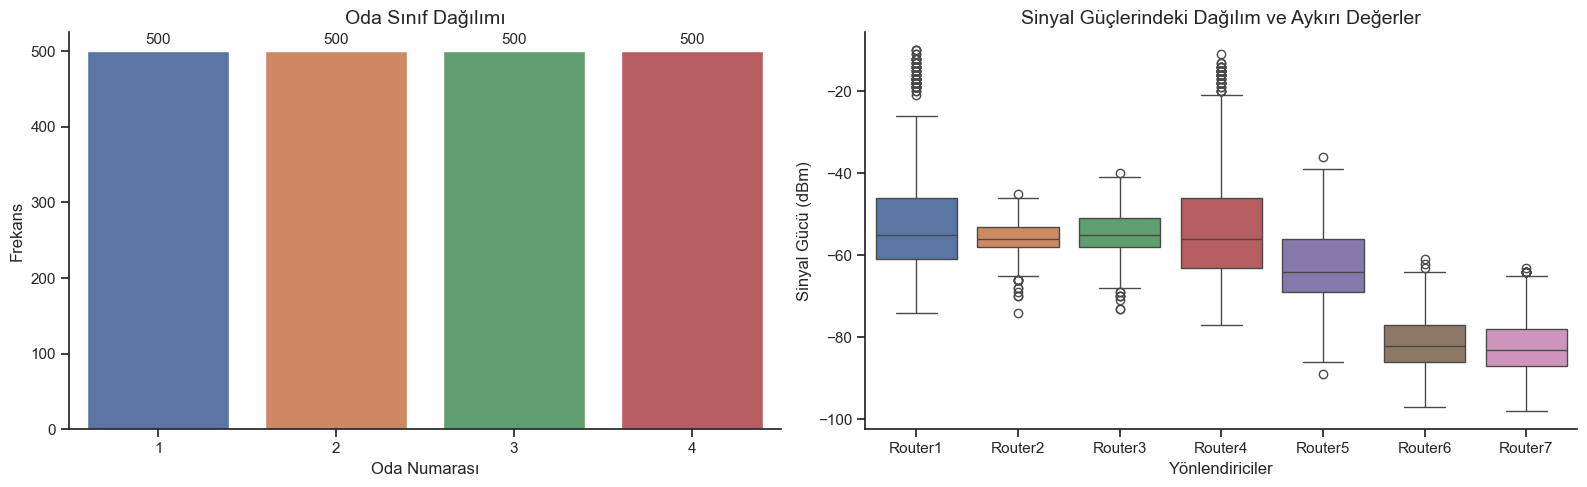

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Sınıf Dağılımı Grafiği
sns.countplot(data=df, x='Room', palette="deep", ax=axes[0])
axes[0].set_title("Oda Sınıf Dağılımı")
axes[0].set_xlabel("Oda Numarası")
axes[0].set_ylabel("Frekans")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Aykırı Değerler (Boxplot)
sns.boxplot(data=df.drop('Room', axis=1), palette="deep", ax=axes[1])
axes[1].set_title("Sinyal Güçlerindeki Dağılım ve Aykırı Değerler")
axes[1].set_ylabel("Sinyal Gücü (dBm)")
axes[1].set_xlabel("Yönlendiriciler")

plt.tight_layout()
plt.show()

### 3. Çok Boyutlu Uzayın Haritalanması (t-SNE)
7 farklı yönlendiriciden gelen sinyaller, cihazın konumunu 7 boyutlu bir uzayda tanımlar. **t-SNE** algoritması kullanılarak bu 7 boyut, aralarındaki fiziksel mesafe korunarak 2 boyuta indirgenmiştir.

t-SNE mesafe tabanlı bir algoritma olduğu için, boyut indirgeme işleminden önce veriler `StandardScaler` ile ölçeklendirilmiştir.

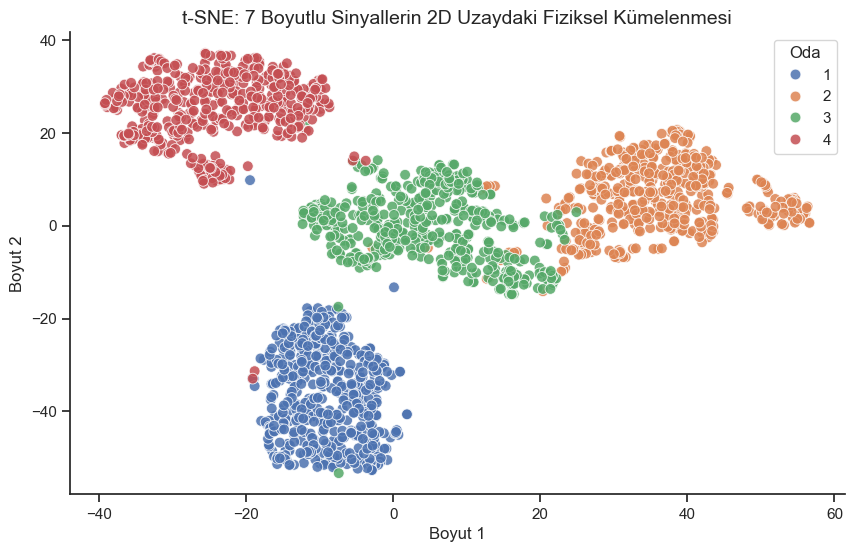

In [42]:
# t-SNE öncesi verinin ölçeklendirilmesi
scaler_tsne = StandardScaler()
X_scaled = scaler_tsne.fit_transform(df.drop('Room', axis=1))

tsne = TSNE(n_components=2, random_state=42, perplexity=40)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df['Room'], palette="deep", s=60, alpha=0.85)
plt.title("t-SNE: 7 Boyutlu Sinyallerin 2D Uzaydaki Fiziksel Kümelenmesi")
plt.xlabel("Boyut 1")
plt.ylabel("Boyut 2")
plt.legend(title="Oda")
plt.show()

### 4. Veri Bölme, Sızıntı Önleme ve Çapraz Doğrulama
Makine öğrenmesi modellerini doğrudan eğitmek, genellikle hatalara yol açar. Bu projede, Veri Sızıntısı hatasını engellemek için bir altyapı kurulmuştur.

* **Pipeline Mimarisi:** Verinin ölçeklendirilmesi (`StandardScaler`) işlemi tüm veriye değil, sadece eğitim aşamasındaki verilere uygulanacak şekilde kapsüllenmiştir. Böylece test verisinin bilgileri eğitime sızamaz.
* **5-Katlı Çapraz Doğrulama (5-Fold CV):** Modeller, şans eseri başarılı olmadıklarını kanıtlamak için verinin farklı parçalarında 5 kez test edilir.

Bu aşamada Lojistik Regresyon, KNN, SVM, Karar Ağaçları ve Random Forest algoritmaları adil olarak test karşılaştırılmaktadır.

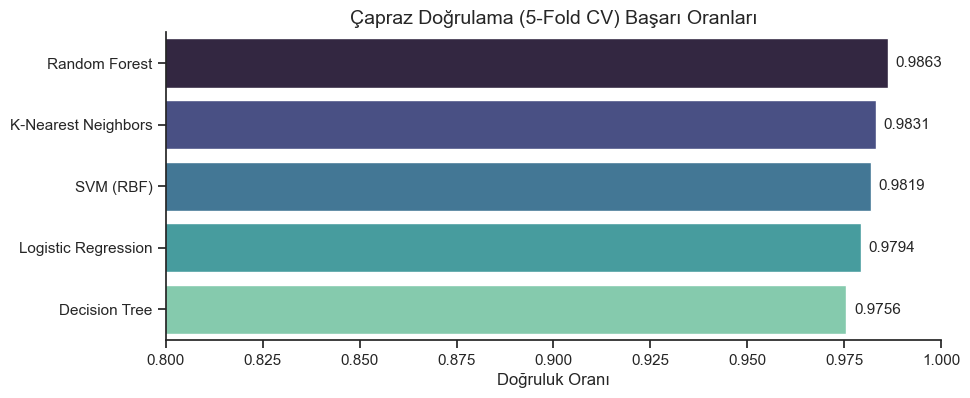

In [43]:
X = df.drop('Room', axis=1)
y = df['Room']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "SVM (RBF)": SVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring_metrics = {
    'Accuracy': 'accuracy',
    'Precision': 'precision_macro',
    'Recall': 'recall_macro',
    'F1 Score': 'f1_macro'
}

results_list = []

for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])

    cv_results = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring_metrics)

    results_list.append({
        "Model": name,
        "Accuracy": cv_results['test_Accuracy'].mean(),
        "Precision": cv_results['test_Precision'].mean(),
        "Recall": cv_results['test_Recall'].mean(),
        "F1 Score": cv_results['test_F1 Score'].mean()
    })

df_results = pd.DataFrame(results_list).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
df_melted = df_results.melt(id_vars="Model", var_name="Metrik", value_name="Skor")

plt.figure(figsize=(10, 4))
ax = sns.barplot(x="Accuracy", y="Model", data=df_results, palette="mako")
plt.title("Çapraz Doğrulama (5-Fold CV) Başarı Oranları")
plt.xlabel("Doğruluk Oranı")
plt.ylabel("")
plt.xlim(0.8, 1.0)
for i, v in enumerate(df_results["Accuracy"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va='center')
plt.show()

### 5. Algoritma Performanslarının Görsel Karşılaştırması
Bir önceki adımda hesaplanan çapraz doğrulama sonuçları, sadece genel doğruluk (Accuracy) üzerinden değil, modelin hassasiyetini gösteren çok boyutlu metriklerle (Precision, Recall, F1-Score) birlikte görselleştirilir.

Bu grafik, modellerin performanslarını en dürüst şekilde yan yana koyar ve projenin "Lider Modelini" veriye dayalı olarak seçmemizi sağlar.

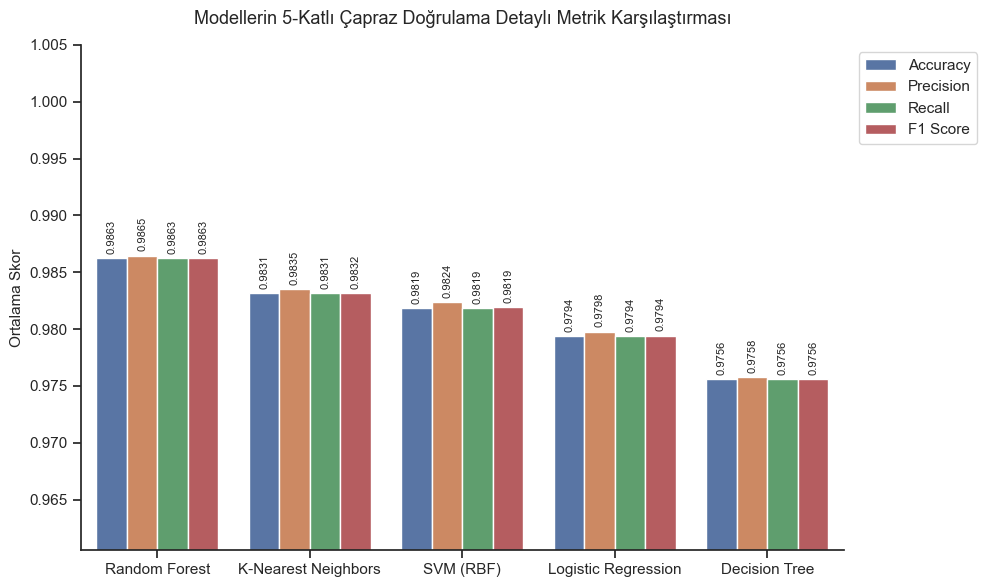

In [44]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(data=df_melted, x="Model", y="Skor", hue="Metrik", palette="deep")

min_score = df_melted["Skor"].min()
plt.ylim(min_score - 0.015, 1.005)

plt.title("Modellerin 5-Katlı Çapraz Doğrulama Detaylı Metrik Karşılaştırması", fontsize=13, pad=15)
plt.ylabel("Ortalama Skor", fontsize=11)
plt.xlabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3, rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

### 6. Dinamik Lider Seçimi ve Hiperparametre Optimizasyonu
Karşılaştırma sonucunda en yüksek Accuracy puanını alan algoritma, sistem tarafından **"Lider Model"** olarak seçilir.

Lider modelin performansını maksimize etmek için **GridSearchCV** kullanılarak algoritmanın en iyi iç parametre kombinasyonları (örneğin ağaç derinliği, komşu sayısı veya ceza parametresi) test edilir ve model optimize edilir.

Optimize Edilen Lider Model: Random Forest
--------------------------------------------------
Bulunan En İyi Parametreler:
  • max_depth: None
  • min_samples_split: 2
  • n_estimators: 50
--------------------------------------------------


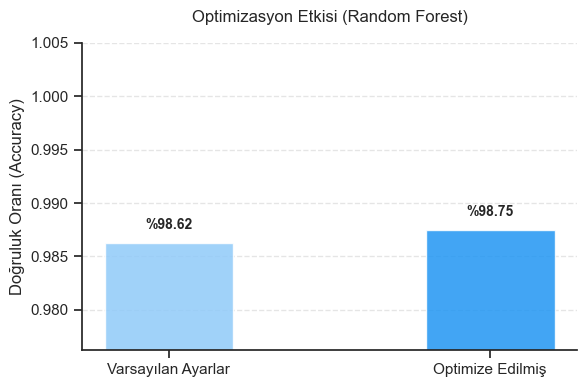

In [50]:
best_model_name = df_results.iloc[0]["Model"]
best_default_score = df_results.iloc[0]["Accuracy"]

param_grids = {
    "K-Nearest Neighbors": {
        'classifier__n_neighbors': [3, 5, 7, 9],
        'classifier__weights': ['uniform', 'distance']
    },
    "Random Forest": {
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [None, 10, 20],
        'classifier__min_samples_split': [2, 5]
    },
    "SVM (RBF)": {
        'classifier__C': [0.1, 1, 10, 100],
        'classifier__gamma': ['scale', 'auto', 0.1]
    }
}

winner_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', models[best_model_name])
])

if best_model_name in param_grids:
    grid_search = GridSearchCV(winner_pipeline, param_grids[best_model_name], cv=cv, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train, y_train)
    final_model = grid_search.best_estimator_

    optimized_score = grid_search.best_score_

    print(f"Optimize Edilen Lider Model: {best_model_name}")
    print("-" * 50)
    print("Bulunan En İyi Parametreler:")
    for key, value in grid_search.best_params_.items():
        clean_key = key.replace('classifier__', '')
        print(f"  • {clean_key}: {value}")
    print("-" * 50)

    # --- ÖNCESİ / SONRASI GRAFİĞİ ---
    fig, ax = plt.subplots(figsize=(6, 4))
    scores = [best_default_score, optimized_score]
    labels = ['Varsayılan Ayarlar', 'Optimize Edilmiş']

    colors = ['#90CAF9', '#2196F3']

    bars = ax.bar(labels, scores, color=colors, width=0.4, alpha=0.85, edgecolor='white')

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.001,
                f'%{height*100:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    min_score = min(scores)
    ax.set_ylim(min_score - 0.01, 1.005)
    ax.set_ylabel('Doğruluk Oranı (Accuracy)')
    ax.set_title(f'Optimizasyon Etkisi ({best_model_name})', fontsize=12, pad=15)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

else:
    print(f"Varsayılan parametreler kullanılıyor: {best_model_name}")
    final_model = winner_pipeline
    final_model.fit(X_train, y_train)

### 7. Yönlendiricilerin Özellik Önemi (Feature Importance)
Kapalı alan konumlandırmada tüm yönlendiricilerin sisteme eşit katkı sağlaması beklenemez. Bazı yönlendiriciler stratejik konumlarda bulunurken, bazıları yüksek gürültülü veya zayıf sinyal üretiyor olabilir. Sinyal verilerinin oda ayrımında en çok hangi yönlendiricinin ayırt edici olduğunu görmek projenin fiziksel yorumlanabilirliği için çok önemlidir.

Bunu yorumlayabilmek için diğer modellerden tamamen bağımsız bir Random Forest modeli eğitilmiştir. Ağaç tabanlı bu modelin Gini Impurity (Safsızlık Azalması) skoru kullanılarak, yönlendiricilerin önem dereceleri sıralanmış ve sisteme en çok bilgi sağlayan cihazlar tespit edilmiştir.

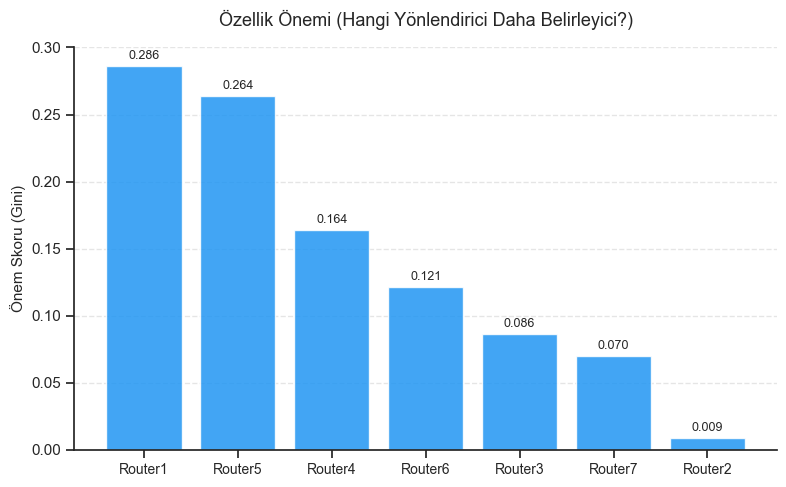

In [46]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])
rf_pipeline.fit(X_train, y_train)

feature_names = [f'Router{i}' for i in range(1, 8)]
importances = rf_pipeline.named_steps['classifier'].feature_importances_
indices = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(range(7), importances[indices], color='#2196F3', alpha=0.85, edgecolor='white')

for bar, val in zip(bars, importances[indices]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(range(7))
ax.set_xticklabels([feature_names[i] for i in indices], fontsize=10)
ax.set_ylabel('Önem Skoru (Gini)', fontsize=11)
ax.set_title('Özellik Önemi (Hangi Yönlendirici Daha Belirleyici?)', fontsize=13, pad=15)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 8. Nihai Test Sınavı ve Kapsamlı Hata Analizi
Optimizasyonu tamamlanmış Lider Model, öğrenme aşamasında hiç görmediği %20'lik Bağımsız Test Seti ile nihai sınava sokulur.

* **Karmaşıklık Matrisi (Confusion Matrix):** Modelin, hangi fiziksel odaları birbirine daha çok karıştırdığını sayısal olarak gösterir.
* **Sınıflandırma Isı Haritası:** Her bir oda için ayrı ayrı tespit başarısı (Precision, Recall) detaylandırılarak projenin final performansı tescillenir.

Nihai Modelin Gerçek Dünya Simülasyonu (Test Seti) Başarısı: %98.00



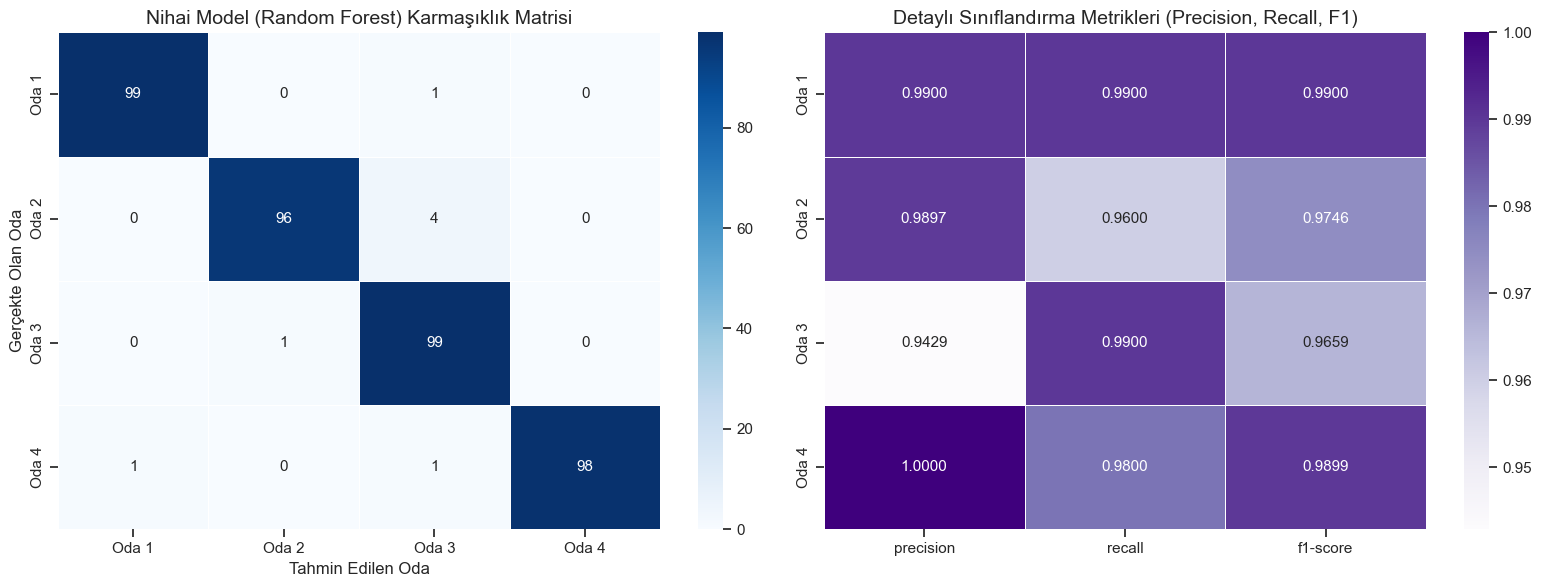

In [47]:
y_pred_final = final_model.predict(X_test)
print(f"Nihai Modelin Gerçek Dünya Simülasyonu (Test Seti) Başarısı: %{accuracy_score(y_test, y_pred_final)*100:.2f}\n")

# Veri seti gereği hedef değişken 4 odayı içerir
room_labels = [f'Oda {i}' for i in range(1, 5)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Karmaşıklık Matrisi Grafiği
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=0.5,
            xticklabels=room_labels, yticklabels=room_labels, ax=axes[0])
axes[0].set_title(f"Nihai Model ({best_model_name}) Karmaşıklık Matrisi")
axes[0].set_xlabel("Tahmin Edilen Oda")
axes[0].set_ylabel("Gerçekte Olan Oda")

# 2. Sınıflandırma Raporu (Classification Report) Isı Haritası
report_dict = classification_report(y_test, y_pred_final, target_names=room_labels, output_dict=True)

# Sadece odalara ait satırları almak için DataFrame filtrelemesi
report_df = pd.DataFrame(report_dict).iloc[:-1, :4].T
sns.heatmap(report_df, annot=True, cmap='Purples', fmt='.4f', linewidths=0.5, ax=axes[1])
axes[1].set_title("Detaylı Sınıflandırma Metrikleri (Precision, Recall, F1)")

plt.tight_layout()
plt.show()